In [1]:
#recherche de la racine du projet pour trouver le dossier src
import sys
sys.path.append("..")

#importation des bibliothèques nécessaires 
import pandas as pd
import matplotlib.pyplot as plt

#importation de la fonction Load_imdb depuis le module data dans le dossier src
from src.data import load_imdb

In [2]:
#chargement du jeu de données IMDB
df = load_imdb()
df.head()

,review,label
0,"A very, very, very slow-moving, aimless movie ...",0
1,Not sure who was more lost - the flat characte...,0
2,Attempting artiness with black & white and cle...,0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo i...,1


In [3]:
print(df.shape)
print(df["label"].value_counts())
df.info()

(1000, 2)
label
0    500
1    500
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  1000 non-null   object
 1   label   1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


In [4]:
#recherche des avis vides 
vides = df["review"].str.strip().eq("")
print("Avis vides :", vides.sum())

Avis vides : 0


In [5]:
#recherche des avis duppliqués 
print("Doublons exacts :", df.duplicated().sum())
#recherche des avis duppliqués avec le même texte mais des labels différents
print("Même texte, labels différents :", df.duplicated(subset="review").sum() - df.duplicated().sum())
df[df.duplicated(subset="review", keep=False)].sort_values("review")

Doublons exacts : 3
Même texte, labels différents : 0


,review,label
125,10/10,1
788,10/10,1
90,Definitely worth checking out.,1
363,Definitely worth checking out.,1
572,Not recommended.,0
585,Not recommended.,0


3 doublons exacts trouvés (avis courts et génériques, probablement écrits par des personnes différentes). Aucun conflit de label. Supprimés pour éviter qu'un même texte se retrouve à la fois dans le train et dans le test.

In [6]:
#suppresion des doublons exacts 
avant = len(df)
df = df.drop_duplicates(subset="review").reset_index(drop=True)

print(f"Lignes supprimées : {avant - len(df)}")
print(df.shape)
print(df["label"].value_counts())

Lignes supprimées : 3
(997, 2)
label
0    499
1    498
Name: count, dtype: int64


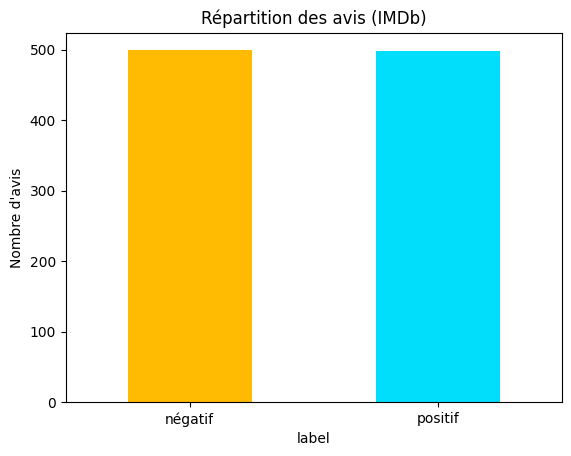

In [7]:
counts = df["label"].map({0: "négatif", 1: "positif"}).value_counts()

counts.plot(kind="bar", color=["#ffbb01", "#00defc"])
plt.title("Répartition des avis (IMDb)")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.show()

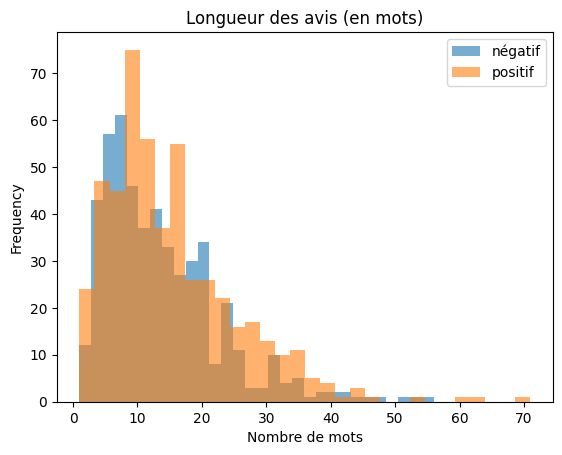

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,499.0,13.605210,9.030429,1.0,7.0,11.0,19.0,56.0
1,498.0,15.178715,10.090844,1.0,8.0,13.0,20.0,71.0


In [8]:
df["nb_mots"] = df["review"].str.split().str.len()

df.groupby("label")["nb_mots"].plot(kind="hist", bins=30, alpha=0.6, legend=True)
plt.title("Longueur des avis (en mots)")
plt.xlabel("Nombre de mots")
plt.legend(["négatif", "positif"])
plt.show()

df.groupby("label")["nb_mots"].describe()

## Conclusion de l'exploration — IMDb (UCI)

**Source** : Sentiment Labelled Sentences, UCI Machine Learning Repository (Kotzias, 2015). Fichier `imdb_labelled.txt`.

| Indicateur | Valeur |
|---|---|
| Lignes brutes | 1 000 |
| Avis vides | 0 |
| Doublons supprimés | 3 |
| Lignes après nettoyage | **997** |
| Négatifs / Positifs | 499 / 498 |
| Longueur moyenne | ≈ 14,4 mots |

| Classe | Moyenne | Médiane | Min | Max |
|---|---|---|---|---|
| Négatif | 13,6 mots | 11 | 1 | 56 |
| Positif | 15,2 mots | 13 | 1 | 71 |

**Observations**
- Les classes sont quasi parfaitement équilibrées. La baseline majoritaire aura donc une accuracy d'environ 50 % et un F1 macro d'environ 0,33.
- Les 3 doublons sont des avis courts et génériques (« 10/10 », « Not recommended. »), sans conflit de label. Ils ont été supprimés pour éviter qu'un même texte se retrouve à la fois dans le train et dans le test.
- Les avis sont très courts : 75 % font 20 mots ou moins, et certains ne font qu'un seul mot. Le modèle aura peu de contexte, ce qui risque de poser problème pour l'ironie, les négations et les avis d'un mot.
- Les avis positifs sont légèrement plus longs que les négatifs (≈ +1,5 mot en moyenne), mais les deux distributions se recouvrent presque entièrement : la longueur seule ne permet pas de distinguer le sentiment.

**Points forts** : dataset léger, propre, rapide à entraîner.
**Points faibles** : petit volume (997 avis), ce qui donne un jeu de test d'environ 200 avis seulement. Les métriques seront donc assez instables.

In [9]:
#export du jeu de données nettoyé
df.drop(columns="nb_mots").to_csv("../data/imdb/imdb_clean.csv", index=False)

## Comparaison IMDb vs Allociné

|Critère | IMDb (UCI) | Allociné |
|---|---|---|
| Langue | Anglais | Français |
| Volume après nettoyage | 997 | ~199 000 |
| Équilibre des classes | 499 / 498 | ~50 / 50 |
| Longueur moyenne | ~14 mots | ~91 mots |
| Longueur médiane | 11 à 13 mots | 64 à 69 mots |
| Split | À faire (80/20 stratifié) | Fourni (train / validation / test) |
| Jeu de test | ~200 avis | ~20 000 (ou échantillon de 5 000) |
| Temps d'entraînement | Instantané | Quelques secondes à minutes selon l'échantillon |
| Stabilité des métriques | Faible (petit test) | Bonne |

Choix retenu : IMDb, pour sa légèreté et sa rapidité d'itération. Limite : le jeu de test est petit (~200 avis).